In [1]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Load dataset
file_path = r"C:\Users\LATO\Documents\Customer Churn\data\customer-churn-data.csv"
df = pd.read_csv(file_path)

# Convert TotalCharges to numeric; blank values become NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Define target: Yes = 1, No = 0
y = df["Churn"].map({"No": 0, "Yes": 1})

# Remove target and customer identifier from predictors
X = df.drop(columns=["Churn", "customerID"])

# Check target mapping
print("Dataset shape:", df.shape)
print("\nMissing target values:", y.isna().sum())
print("Missing TotalCharges:", X["TotalCharges"].isna().sum())
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))


Dataset shape: (7043, 21)

Missing target values: 0
Missing TotalCharges: 11

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target percentages:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [2]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

print("\nMissing values in training data:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])


Training features: (5634, 19)
Testing features: (1409, 19)

Training churn rate: 26.54 %
Testing churn rate: 26.54 %

Missing values in training data:
TotalCharges    8
dtype: int64


In [3]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify column types from training data
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully.


In [4]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

print("Baseline Model Results")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))
print("Precision:", round(precision_score(y_test, baseline_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, baseline_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, baseline_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, baseline_probabilities), 4))


Baseline Model Results
----------------------
Accuracy: 0.7346
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.5


In [5]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate each model
results = []
trained_models = {}

for name, classifier in models.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
1,Random Forest,0.7757,0.6000,0.4652,0.5241,0.8186


Confusion Matrix:
[[926 109]
 [165 209]]


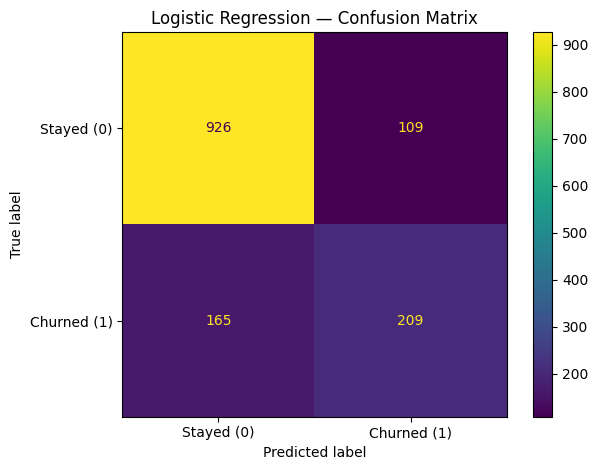


Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.85      0.89      0.87      1035
 Churned (1)       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [6]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Select the current best model
best_model = trained_models["Logistic Regression"]

# Predictions at the default threshold of 0.5
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display_labels = ["Stayed (0)", "Churned (1)"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=display_labels,
    zero_division=0
))


In [7]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

# Generate training-only out-of-fold probabilities
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    clone(best_model),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Compare thresholds using training-only predictions
threshold_results = []

for threshold in np.arange(0.20, 0.61, 0.05):
    predictions = (oof_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1-score
0,0.20,0.4751,0.8548,0.6108
1,0.25,0.5096,0.8167,0.6276
2,0.30,0.5408,0.7666,0.6342
3,0.35,0.5705,0.7171,0.6354
4,0.40,0.5940,0.6635,0.6269
5,0.45,0.6236,0.6007,0.6119
6,0.50,0.6527,0.5431,0.5929
7,0.55,0.6852,0.4863,0.5689
8,0.60,0.7102,0.3967,0.5090


In [8]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Selected using cross-validation on the training set
best_threshold = 0.35

# Get churn probabilities for the test set
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Convert probabilities into predictions using threshold 0.35
test_predictions_tuned = (
    test_probabilities >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)
print("Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions_tuned,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

print("Accuracy:", round(
    accuracy_score(y_test, test_predictions_tuned), 4
))
print("Precision:", round(
    precision_score(y_test, test_predictions_tuned, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, test_predictions_tuned, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, test_predictions_tuned, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

Selected Threshold: 0.35
Confusion Matrix:
[[814 221]
 [110 264]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.79      0.83      1035
     Churned       0.54      0.71      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.77      1409

Accuracy: 0.7651
Precision: 0.5443
Recall: 0.7059
F1-score: 0.6147
ROC-AUC: 0.8419


In [9]:
comparison_df = pd.DataFrame([
    {
        "Threshold": 0.50,
        "Accuracy": 0.8055,
        "Precision": 0.6572,
        "Recall": 0.5588,
        "F1-score": 0.6040,
        "ROC-AUC": 0.8419
    },
    {
        "Threshold": 0.35,
        "Accuracy": 0.7651,
        "Precision": 0.5443,
        "Recall": 0.7059,
        "F1-score": 0.6147,
        "ROC-AUC": 0.8419
    }
])

display(comparison_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.50,0.8055,0.6572,0.5588,0.6040,0.8419
1,0.35,0.7651,0.5443,0.7059,0.6147,0.8419


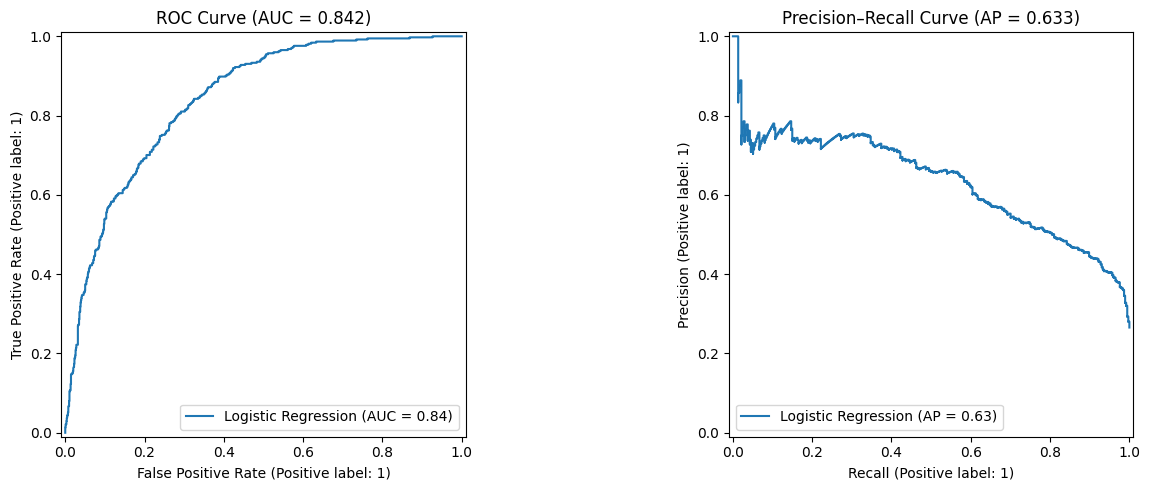

ROC-AUC: 0.8419
Average Precision: 0.6334


In [10]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    average_precision_score
)

# Use the test-set probabilities from the trained Logistic Regression model
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC and Average Precision
roc_auc = roc_auc_score(y_test, test_probabilities)
avg_precision = average_precision_score(y_test, test_probabilities)

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    ax=axes[0],
    name="Logistic Regression"
)
axes[0].set_title(f"ROC Curve (AUC = {roc_auc:.3f})")

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    ax=axes[1],
    name="Logistic Regression"
)
axes[1].set_title(f"Precision–Recall Curve (AP = {avg_precision:.3f})")

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(avg_precision, 4))


,Feature,Importance Mean,Importance Std
4,tenure,0.1694,0.0051
7,InternetService,0.0393,0.0106
14,Contract,0.0325,0.0034
17,MonthlyCharges,0.0306,0.0068
18,TotalCharges,0.0131,0.0022
8,OnlineSecurity,0.0040,0.0018
11,TechSupport,0.0038,0.0010
13,StreamingMovies,0.0038,0.0019
12,StreamingTV,0.0033,0.0022
16,PaymentMethod,0.0031,0.0015


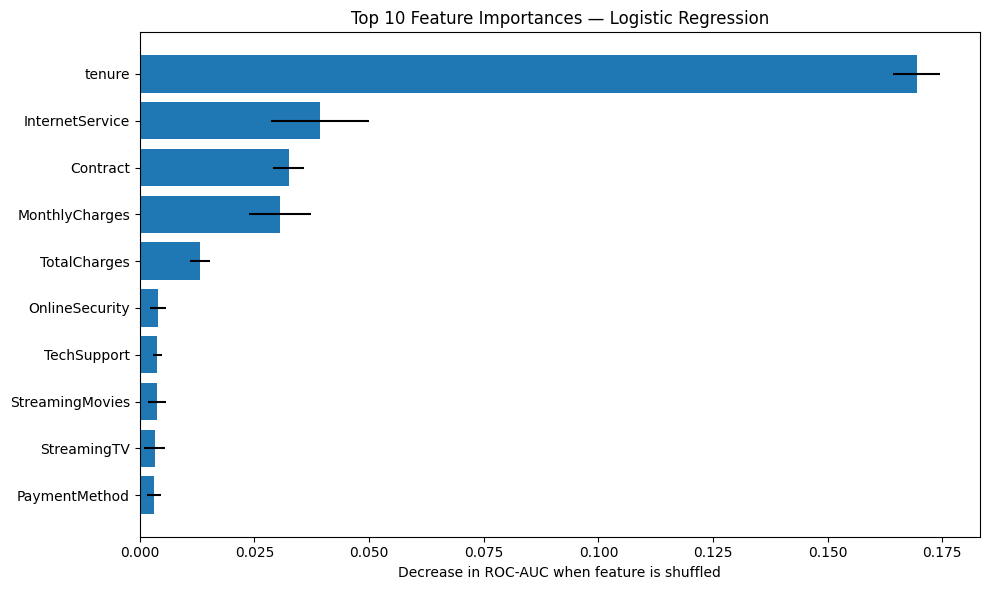

In [12]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Calculate permutation importance without parallel processing
perm_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Create the importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
}).sort_values("Importance Mean", ascending=False)

display(importance_df.round(4))

# Plot the 10 most important features
top_features = importance_df.head(10).sort_values("Importance Mean")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)
plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.title("Top 10 Feature Importances — Logistic Regression")
plt.tight_layout()
plt.show()


In [13]:

import joblib
from pathlib import Path

# Save the trained pipeline
project_dir = Path(r"C:\Users\LATO\Documents\Customer Churn")
model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "customer_churn_logistic_regression.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("Selected classification threshold:", best_threshold)


Model saved successfully!
Location: C:\Users\LATO\Documents\Customer Churn\models\customer_churn_logistic_regression.pkl
Selected classification threshold: 0.35


In [14]:

import joblib
import pandas as pd
from pathlib import Path

# Load the saved model
model_path = Path(
    r"C:\Users\LATO\Documents\Customer Churn\models\customer_churn_logistic_regression.pkl"
)

loaded_model = joblib.load(model_path)

# Select three customers from the test set
sample_customers = X_test.iloc[:3].copy()

# Predict churn probabilities
churn_probabilities = loaded_model.predict_proba(sample_customers)[:, 1]

# Apply the selected threshold
churn_predictions = (churn_probabilities >= 0.35).astype(int)

# Display results
prediction_results = pd.DataFrame({
    "Actual Churn": y_test.loc[sample_customers.index].map({
        0: "No",
        1: "Yes"
    }),
    "Churn Probability (%)": (churn_probabilities * 100).round(2),
    "Predicted Churn": pd.Series(
        churn_predictions,
        index=sample_customers.index
    ).map({0: "No", 1: "Yes"})
})

display(prediction_results)
print("Saved model loaded and tested successfully!")


,Actual Churn,Churn Probability (%),Predicted Churn
437,No,4.53,No
2280,No,68.44,Yes
2235,No,5.87,No


Saved model loaded and tested successfully!


# Customer Churn Prediction — Final Summary

## 1. Project Objective
Develop a machine learning model to predict customer churn and identify customers who may need retention support.

## 2. Dataset Overview
- Total customers: 7,043
- Input features: 19
- Target variable: Churn
- Customers who churned: 1,869 (26.54%)
- Customers who stayed: 5,174 (73.46%)

## 3. Data Preparation
- Converted `TotalCharges` to numeric format.
- Imputed missing numeric and categorical values.
- Scaled numeric features and one-hot encoded categorical features.
- Excluded `customerID` from model inputs.
- Used a stratified 80/20 training-test split.

## 4. Models Evaluated
- Dummy Classifier — baseline
- Logistic Regression — best-performing evaluated model
- Random Forest — comparison model

## 5. Final Model Performance
**Selected model:** Logistic Regression

**Selected classification threshold:** 0.35

- Accuracy: 76.51%
- Precision: 54.43%
- Recall: 70.59%
- F1-score: 61.47%
- ROC-AUC: 84.19%
- Average Precision: 63.34%

The selected threshold improves churn detection compared with the default 0.50 threshold, while increasing false-positive predictions.

## 6. Key Findings
- Tenure was the most important predictive feature.
- Internet service type and contract type were important predictors.
- Monthly charges and total charges also contributed to predictions.
- Customers with shorter tenure showed higher churn risk in the exploratory analysis.
- Permutation importance measures predictive contribution, not causation.

## 7. Business Recommendations
- Provide onboarding support during customers' early months.
- Offer suitable contract incentives to month-to-month customers.
- Investigate customer concerns about internet service and monthly charges.
- Prioritize retention outreach for customers with high predicted churn risk.
- Evaluate campaign costs and outcomes before deploying retention strategies.

## 8. Model Limitations
- The model may produce false positives and false negatives.
- Performance may change on future customer data.
- The selected threshold reflects a trade-off between precision and recall.
- Predictions indicate risk, not certainty or causation.

## 9. Deliverables
- Exploratory data analysis
- Statistical analysis
- Predictive modeling and evaluation
- ROC and Precision–Recall curves
- Permutation feature importance
- Saved preprocessing and Logistic Regression pipeline

**Conclusion:** The project demonstrates an end-to-end customer churn prediction workflow using Python, Pandas, Scikit-learn, statistical analysis, and model evaluation.
